In [13]:
# load all libraries and modules
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import shutil
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, sosfreqz
from scipy.interpolate import interp1d

from modules import gfLoader
from modules import configLoader
from modules import createDB

In [14]:
def bandpass_zero_phase(x,dt,fmin=2.0,fmax=8.0,order=4):
    """
    Zero-phase Butterworth bandpass filter.

    Filtering is done with sosfiltfilt, therefore no phase
    shift should be introduced.
    """

    fs = 1.0 / dt

    sos = butter(order,[fmin, fmax],btype="bandpass",fs=fs,output="sos")

    return sosfiltfilt(sos, x)

def load_qseis_trace_at_distance(splitAll,basePath,zTarget,rTarget,component):

    gfInfo = gfLoader.getGFFilesForDepth(splitAll,zTarget,rTarget,rTarget,basePath)

    if len(gfInfo["depths"]) != 1:
        raise RuntimeError(
            f"Receiver depth {zTarget} is not an exact "
            f"QSEIS DB depth: {gfInfo['depths']}"
        )

    depth = gfInfo["depths"][0]

    files, runInfo = gfLoader.getGFFileListForDepth(gfInfo,depth,[component])

    if len(files) == 0:
        raise RuntimeError(f"No QSEIS file found for r={rTarget}")

    chosen = None

    for irun, run in enumerate(runInfo):
        if run["x_start"] <= rTarget <= run["x_end"]:
            chosen = irun
            break

    if chosen is None:
        raise RuntimeError(f"No QSEIS run contains r={rTarget}")

    run = runInfo[chosen]
    filePath = files[chosen]

    data = np.loadtxt(filePath,skiprows=1)

    t = data[:, 0]
    xx = data[:, 1:]

    distVec = np.asarray(run["distVec"])

    # Use exact receiver column if available
    iExact = np.where(np.isclose(distVec, rTarget))[0]

    if len(iExact) > 0:
        trace = xx[:, iExact[0]]
    else:
        trace = np.empty(len(t))
        for it in range(len(t)):
            trace[it] = np.interp(rTarget,distVec,xx[it, :])

    return t, trace

def load_specfem_trace(outputDir, station, component):
    """
    Load one SPECFEM displacement seismogram.

    Expected filename format is something like:
        DB.S003.HXZ.semd
        DB.S003.HXX.semd
    """

    pattern = os.path.join(outputDir,f"*.{station}.{component}.semd")

    files = glob.glob(pattern)

    if len(files) == 0:
        raise FileNotFoundError(
            f"No SPECFEM file found for "
            f"station={station}, component={component}\n"
            f"Pattern: {pattern}"
        )

    if len(files) > 1:
        raise RuntimeError(f"More than one SPECFEM file found:\n{files}")

    data = np.loadtxt(files[0])

    t = data[:, 0]
    u = data[:, 1]

    print(f"Loaded: {files[0]}")

    return t, u

def interp_complex(freqOld, zOld, freqNew):

    zr = np.interp(freqNew,freqOld,np.real(zOld))
    zi = np.interp(freqNew,freqOld,np.imag(zOld))
    return zr + 1j*zi


In [15]:
# ============================================================
# CELL — Dedicated QSEIS validation run at several exact offsets
# ============================================================

# ------------------------------------------------------------
# Exact receiver locations wanted for SPECFEM comparison
# ------------------------------------------------------------

rExact = np.array([500.0,1000.0,1500.0,2000.0,2500.0,3000.0,3500.0,4000.0])
zRec = 0.0

# Verify uniform spacing, since QSEIS uses d1, dn, n_points
dr = np.diff(rExact)

if not np.allclose(dr, dr[0]):
    raise ValueError("Dedicated QSEIS run requires uniformly spaced receiver offsets.")

nRecQ = len(rExact)

# ============================================================
# 1. Name/path for validation run
# ============================================================
inputPath = "/home/koley/CavityResults/AllTutOut/QseisSpecfemSeisTest/QseisInpN"
layerName = "QSEIS_validation_offsets"

inputFile = os.path.join(inputPath,layerName + ".dat")
runDir = os.path.join(inputPath,layerName)
os.makedirs(runDir,exist_ok=True)

# ============================================================
# 2. Build velocity model exactly as normal database does
# ============================================================
# load the config file from before
configFile="/home/koley/CavityResults/SphereValidTutorial/SingleForce/configParseHalfSpaceFullFieldHomo.ini"
config = configLoader.load_config(configFile)
velBlock, nLines = createDB.formatVelModel(config.thickness,config.vP,config.vS,config.rho,config.qP,
                                           config.qS)

# ============================================================
# 3. Get same source-radius / integration parameter used
#    by normal surface QSEIS database
# ============================================================

depths, nX, nY, gridSize, sr = createDB.getNXDP(config)

# Surface belongs to first layer
srN = sr[0]

print("Using srN =", srN)

# ============================================================
# 4. Copy normal QSEIS template
# ============================================================

shutil.copy(config.templateFile,inputFile)

with open(inputFile, "r") as f:
    content = f.read()

# ============================================================
# 5. Fill template
# ============================================================

content = content.format(velocity_model = velBlock,n_lines = nLines,
                         receiver_depth = zRec / 1000.0,n_points = nRecQ,# QSEIS expects km
                         d1 = rExact[0]  / 1000.0,dn = rExact[-1] / 1000.0,
                         tmax  = config.tMax,nsamp = config.nSamp,srN = srN)

with open(inputFile, "w") as f:
    f.write(content)

# ============================================================
# 6. Check actual QSEIS receiver positions
# ============================================================

rQCheck = np.linspace(rExact[0],rExact[-1],nRecQ)
print("\nRequested receiver offsets [m]:")
print(rExact)

print("\nQSEIS receiver offsets [m]:")
print(rQCheck)

print("\nExact match:",np.allclose(rExact, rQCheck))

# ============================================================
# 7. Run QSEIS ONCE
# ============================================================

result = createDB.runSingleQseis(layerName,inputPath,config.qseisExe)

print("\nQSEIS return code =",result["returncode"])

if result["returncode"] != 0:
    print(result["stderr"])

Using srN = 24.0

Requested receiver offsets [m]:
[ 500. 1000. 1500. 2000. 2500. 3000. 3500. 4000.]

QSEIS receiver offsets [m]:
[ 500. 1000. 1500. 2000. 2500. 3000. 3500. 4000.]

Exact match: True
[Worker 1275270] Starting job QSEIS_validation_offsets at 17:29:35
[Worker 1275270] Finished job QSEIS_validation_offsets at 17:29:42 (0.1 min, rc=0)

QSEIS return code = 0


In [16]:
# ============================================================
# Physical model
# ============================================================
# comparing Qseis GF to specfem3d

VP = 5000.0 # P-wave velocity units in m/s
VS = 3000.0 # S-wave velocity units in m/s
RHO = 2700.0 # density units in kg/m^3

SOURCE_X = -2000.0 # source x-coorodinate in meters
SOURCE_Y = 0.0 # source y-coordinate in meters

# receiver of primary interest
RECEIVER_X = 2000.0 # receiver x-coordinate in meters
RECEIVER_Y = 0.0 # receiver y-coordinate in meters

# this is necessary becuause we need to the extract the GF from the qseis data at this distance
R_TARGET = np.sqrt((RECEIVER_X - SOURCE_X)**2 +(RECEIVER_Y - SOURCE_Y)**2)

print("Source-receiver distance =", R_TARGET, "m")

# ============================================================
# Frequency band used for comparison
# ============================================================
# main band of interest for comparison is 2-8 Hz
FMIN = 2.0
FMAX = 8.0

# order of the Butterworth filter used for bandpass filtering
BUTTER_ORDER = 4

# ============================================================
# SPECFEM paths
# ============================================================

SPEC_OUTPUT = "/home/koley/specfemRuns/HomoQseisAttn/OUTPUT_FILES"
STATIONS_FILE = "/home/koley/specfemRuns/HomoQseisAttn/DATA/STATIONS"

# in spefem 8 stations were considered at x = (-1500,-1000,-500,0,500,1000,1500,2000) and y = 0
SPEC_STATION = "S007" # so the 4th station output is intersting, naming starts as S000

# just a naming convention HXX is radial, HXZ is vertical, X implies receiver is along x-axis
SPEC_RADIAL_COMPONENT = "HXX"
SPEC_VERTICAL_COMPONENT = "HXZ"

# we save the 5 Hz ricker wavelet used in the specfem simulation to a file for later use
# note that teh specfem wavelet is sampled at 0.001 s
SPEC_STF_FILE = os.path.join(SPEC_OUTPUT,"plot_source_time_function.txt")

# ============================================================
# QSEIS
# ============================================================
# the QSEIS GF database is at the following path
QSEIS_BASE = "/home/koley/CavityResults/AllTutOut/QseisSpecfemSeisTest/QseisInpN"

# depth of the receiver
ZREC = 0.0

# QSEIS saves the GF as five files of fz-2.tr, fz-2.tz, fh-2.tr, fh-2.tt, fh-2.tz
# note that a fz will never produce transverse component along the source-receiver line
QSEIS_RADIAL_COMPONENT = "fz-2.tr"
QSEIS_VERTICAL_COMPONENT = "fz-2.tz"

# QSEIS uses z positive downward;
# SPECFEM uses z positive upward.
FLIP_QSEIS_Z = True

Source-receiver distance = 4000.0 m


QSEIS samples = 2048
QSEIS dt      = 0.019539999999999225
QSEIS t range = 0.0 to 40.0 s


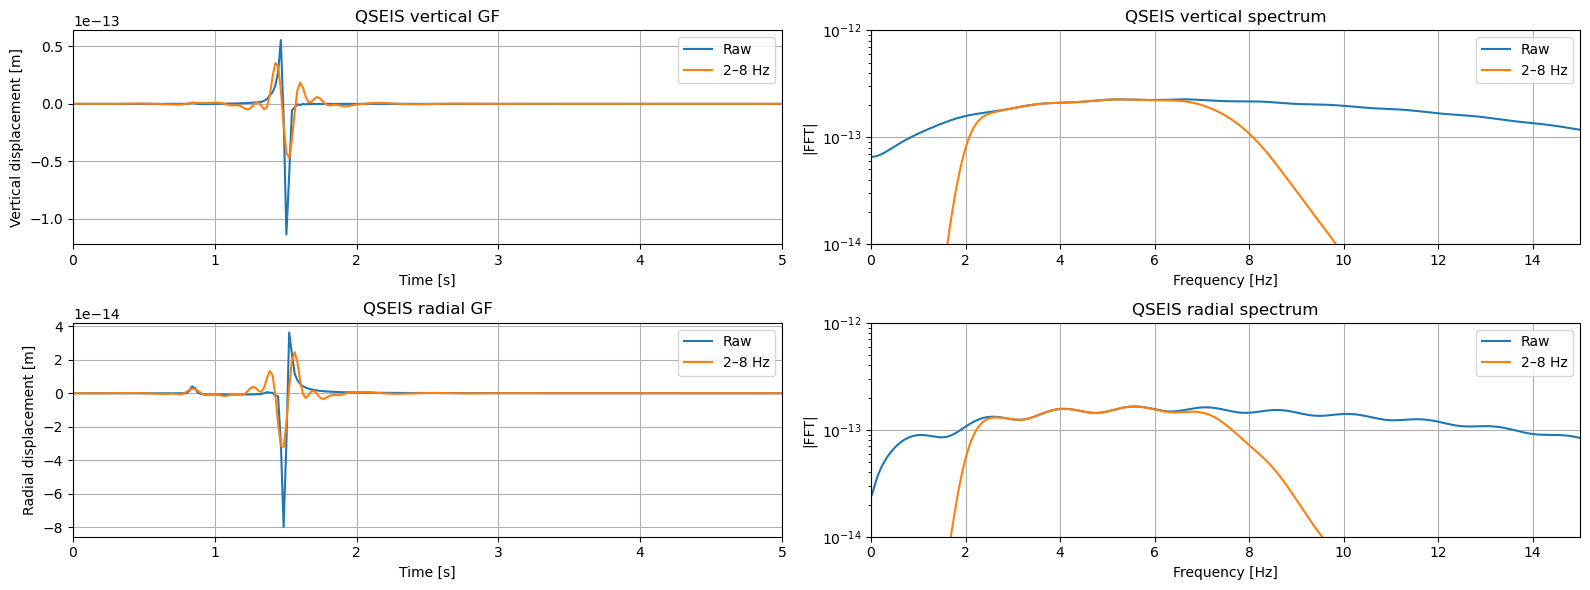

In [17]:
# ============================================================
# Load QSEIS raw GF, filter 2–8 Hz, plot time + FFT
# ============================================================

# ------------------------------------------------------------
# Load raw QSEIS traces
# ------------------------------------------------------------

#tQ, qR_raw = load_qseis_trace_at_distance(splitAll,QSEIS_BASE,ZREC,R_TARGET,QSEIS_RADIAL_COMPONENT)

#tQz, qZ_raw = load_qseis_trace_at_distance(splitAll,QSEIS_BASE,ZREC,R_TARGET,QSEIS_VERTICAL_COMPONENT)

dataZ = np.loadtxt(os.path.join(runDir,"fz-2.tz"),skiprows=1)
dataR = np.loadtxt(os.path.join(runDir,"fz-2.tr"),skiprows=1)

# extract R_TARGET index
rInd = np.where(rQCheck==R_TARGET)[0][0]
qZ_raw = dataZ[:, rInd+1]    # QSEIS z-down -> SPECFEM z-up
qR_raw = dataR[:, rInd+1]

# Time axis
tQz = dataZ[:, 0]
tQ = dataR[:, 0]

if not np.allclose(tQ, tQz):
    raise RuntimeError("QSEIS radial and vertical time axes do not match.")

# ------------------------------------------------------------
# Sign convention
# ------------------------------------------------------------

if FLIP_QSEIS_Z:
    qZ_raw = -qZ_raw

# ------------------------------------------------------------
# Sampling
# ------------------------------------------------------------

dtQ = np.median(np.diff(tQ))

print("QSEIS samples =", len(tQ))
print("QSEIS dt      =", dtQ)
print("QSEIS t range =", tQ[0], "to", tQ[-1], "s")

# apply the same gfLoader window explicitly
W = gfLoader.genWin(tQ,np.array([R_TARGET]),minVel=200.0)[:, 0]

qR_taper = qR_raw * W
qZ_taper = qZ_raw * W
# ------------------------------------------------------------
# Butterworth 2–8 Hz
# ------------------------------------------------------------

qR_filt = bandpass_zero_phase(qR_taper,dtQ)

qZ_filt = bandpass_zero_phase(qZ_taper,dtQ)

# ------------------------------------------------------------
# FFTs
# ------------------------------------------------------------

freqQ = np.fft.rfftfreq(len(tQ),dtQ)

QR_raw_F = np.fft.rfft(qR_taper)
QZ_raw_F = np.fft.rfft(qZ_taper)

QR_filt_F = np.fft.rfft(qR_filt)
QZ_filt_F = np.fft.rfft(qZ_filt)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(2,2,figsize=(16, 6))

# ============================================================
# Top left — vertical time traces
# ============================================================

ax[0, 0].plot(tQ,qZ_taper,label="Raw",linewidth=1.5)
ax[0, 0].plot(tQ,qZ_filt,label="2–8 Hz",linewidth=1.5)

ax[0, 0].set_xlim(0,5)
ax[0, 0].set_xlabel("Time [s]")
ax[0, 0].set_ylabel("Vertical displacement [m]")
ax[0, 0].set_title("QSEIS vertical GF")
ax[0, 0].grid()
ax[0, 0].legend()

# ============================================================
# Top right — vertical FFT
# ============================================================

ax[0, 1].semilogy(freqQ,np.abs(QZ_raw_F),label="Raw")
ax[0, 1].semilogy(freqQ,np.abs(QZ_filt_F),label="2–8 Hz")
ax[0, 1].set_xlim(0.0, 15.0)
ax[0, 1].set_ylim(1e-14, 1e-12)
ax[0, 1].set_xlabel("Frequency [Hz]")
ax[0, 1].set_ylabel("|FFT|")
ax[0, 1].set_title("QSEIS vertical spectrum")
ax[0, 1].grid()
ax[0, 1].legend()

# ============================================================
# Bottom left — radial time traces
# ============================================================

ax[1, 0].plot(tQ,qR_taper,label="Raw",linewidth=1.5)

ax[1, 0].plot(tQ,qR_filt,label="2–8 Hz",linewidth=1.5)
ax[1, 0].set_xlim(0,5)
ax[1, 0].set_xlabel("Time [s]")
ax[1, 0].set_ylabel("Radial displacement [m]")
ax[1, 0].set_title("QSEIS radial GF")
ax[1, 0].grid()
ax[1, 0].legend()

# ============================================================
# Bottom right — radial FFT
# ============================================================

ax[1, 1].semilogy(freqQ,np.abs(QR_raw_F),label="Raw")
ax[1, 1].semilogy(freqQ,np.abs(QR_filt_F),label="2–8 Hz")
ax[1, 1].set_xlim(0.0, 15.0)
ax[1, 1].set_ylim(1e-14, 1e-12)
ax[1, 1].set_xlabel("Frequency [Hz]")
ax[1, 1].set_ylabel("|FFT|")
ax[1, 1].set_title("QSEIS radial spectrum")
ax[1, 1].grid()
ax[1, 1].legend()

plt.tight_layout()
plt.show()

Loaded: /home/koley/specfemRuns/HomoQseisAttn/OUTPUT_FILES/DB.S007.HXZ.semd
Loaded: /home/koley/specfemRuns/HomoQseisAttn/OUTPUT_FILES/DB.S007.HXX.semd

SPECFEM:
number of samples = 1000
dt                = 0.009999990000000292 s
sampling rate     = 100.00010000009708 Hz
time range        = -0.239999995 to 9.75 s


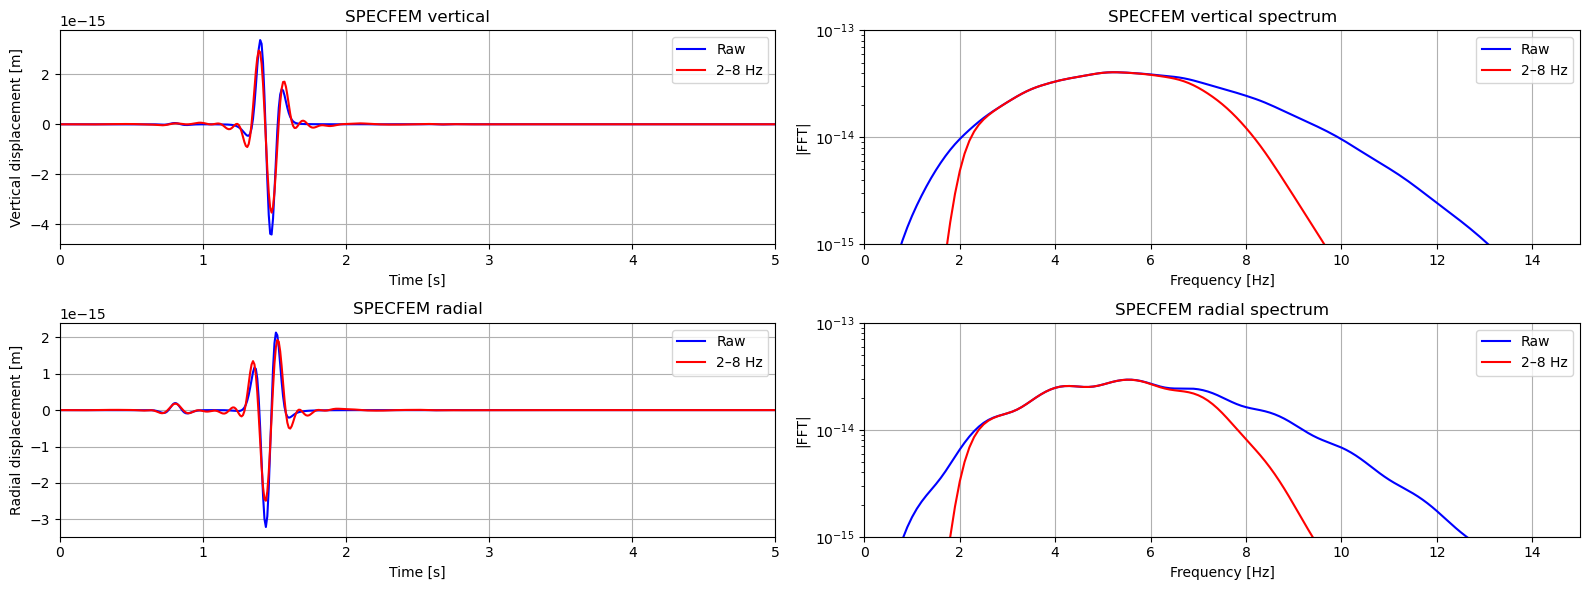

In [18]:
# ============================================================
# Load SPECFEM raw traces, filter 2–8 Hz,
#          and plot time series + FFT
# ============================================================

# ------------------------------------------------------------
# Load raw SPECFEM vertical and radial traces
# ------------------------------------------------------------

# read the vertical and radial traces from the SPECFEM output files
tSpec, specZ_raw = load_specfem_trace(SPEC_OUTPUT,SPEC_STATION,SPEC_VERTICAL_COMPONENT)
tSpecR, specR_raw = load_specfem_trace(SPEC_OUTPUT,SPEC_STATION,SPEC_RADIAL_COMPONENT)

if not np.allclose(tSpec, tSpecR):
    raise RuntimeError("SPECFEM radial and vertical time axes do not match.")

# ------------------------------------------------------------
# Sampling information
# ------------------------------------------------------------

dtSpec = np.median(np.diff(tSpec))

print("\nSPECFEM:")
print("number of samples =", len(tSpec))
print("dt                =", dtSpec, "s")
print("sampling rate     =", 1.0/dtSpec, "Hz")
print("time range        =", tSpec[0], "to", tSpec[-1], "s")

# ------------------------------------------------------------
# Apply ONLY the 2–8 Hz zero-phase Butterworth filter
# ------------------------------------------------------------

specZ_filt = bandpass_zero_phase(specZ_raw,dtSpec)
specR_filt = bandpass_zero_phase(specR_raw,dtSpec)

# ------------------------------------------------------------
# FFTs
# ------------------------------------------------------------

freqSpec = np.fft.rfftfreq(len(tSpec),dtSpec)
SpecZ_raw_F = np.fft.rfft(specZ_raw)
SpecR_raw_F = np.fft.rfft(specR_raw)

SpecZ_filt_F = np.fft.rfft(specZ_filt)
SpecR_filt_F = np.fft.rfft(specR_filt)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(2,2,figsize=(16, 6))

# ============================================================
# (0,0) — Vertical time trace
# ============================================================

ax[0, 0].plot(tSpec,specZ_raw,color="blue",label="Raw",linewidth=1.5)
ax[0, 0].plot(tSpec,specZ_filt,color="red",label="2–8 Hz",linewidth=1.5)
ax[0, 0].set_xlim(0.0, 5.0)
ax[0, 0].set_xlabel("Time [s]")
ax[0, 0].set_ylabel("Vertical displacement [m]")
ax[0, 0].set_title("SPECFEM vertical")
ax[0, 0].grid()
ax[0, 0].legend()

# ============================================================
# (0,1) — Vertical FFT
# ============================================================

ax[0, 1].semilogy(freqSpec,np.abs(SpecZ_raw_F),color="blue",label="Raw")
ax[0, 1].semilogy(freqSpec,np.abs(SpecZ_filt_F),color="red",label="2–8 Hz")

ax[0, 1].set_xlim(0.0, 15.0)
ax[0, 1].set_ylim(1e-15, 1e-13)
ax[0, 1].set_xlabel("Frequency [Hz]")
ax[0, 1].set_ylabel("|FFT|")
ax[0, 1].set_title("SPECFEM vertical spectrum")
ax[0, 1].grid()
ax[0, 1].legend()

# ============================================================
# (1,0) — Radial time trace
# ============================================================

ax[1, 0].plot(tSpec,specR_raw,color="blue",label="Raw",linewidth=1.5)
ax[1, 0].plot(tSpec,specR_filt,color="red",label="2–8 Hz",linewidth=1.5)
ax[1, 0].set_xlim(0.0, 5.0)
ax[1, 0].set_xlabel("Time [s]")
ax[1, 0].set_ylabel("Radial displacement [m]")
ax[1, 0].set_title("SPECFEM radial")
ax[1, 0].grid()
ax[1, 0].legend()

# ============================================================
# (1,1) — Radial FFT
# ============================================================

ax[1, 1].semilogy(freqSpec,np.abs(SpecR_raw_F),color="blue",label="Raw")
ax[1, 1].semilogy(freqSpec,np.abs(SpecR_filt_F),color="red",label="2–8 Hz")
ax[1, 1].set_xlim(0.0, 15.0)
ax[1, 1].set_ylim(1e-15, 1e-13)
ax[1, 1].set_xlabel("Frequency [Hz]")
ax[1, 1].set_ylabel("|FFT|")
ax[1, 1].set_title("SPECFEM radial spectrum")
ax[1, 1].grid()
ax[1, 1].legend()


plt.tight_layout()
plt.show()

SPECFEM STF
  dt          = 0.0009999299999998712 s
  peak time   = 0.0 s
  peak value  = 1.0

QSEIS STF
  dt          = 0.019539999999999225 s
  tau         = 0.0781599999999969 s
  tau/2       = 0.03907999999999845 s
  dt*sum(w)   = 0.9999999999999689


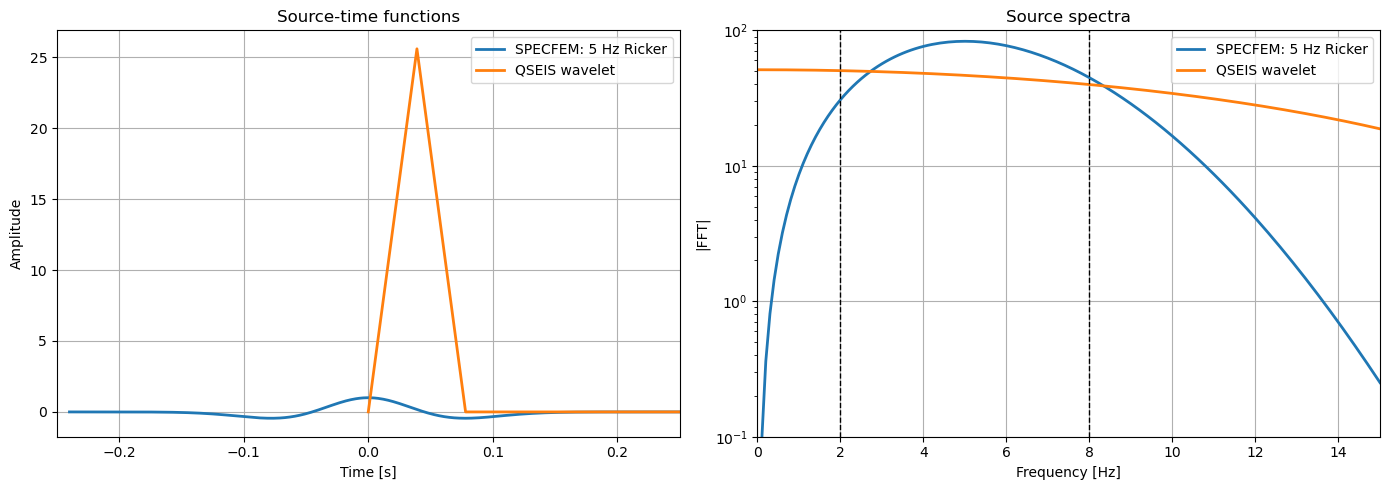

In [19]:
# ============================================================
# Source-time functions in time and frequency
# ============================================================

# ------------------------------------------------------------
# Load exact SPECFEM source-time function
# ------------------------------------------------------------

stfSpecData = np.loadtxt(SPEC_STF_FILE)

tStfSpec = stfSpecData[:, 0]
stfSpec = stfSpecData[:, 1]

dtStfSpec = np.median(np.diff(tStfSpec))

# ------------------------------------------------------------
# Construct the QSEIS source wavelet
#
# QSEIS default:
#
#   w(t) = (2/tau) sin^2(pi*t/tau),  0 < t < tau
#
# with tau = 4 * dtQ
# ------------------------------------------------------------

tauQ = 4.0 * dtQ

# construct it on the native QSEIS time grid
tStfQ = tQ.copy()

stfQ = np.zeros_like(tStfQ)

mask = ((tStfQ > 0.0) &(tStfQ < tauQ))

stfQ[mask] = (2.0/tauQ*np.sin(np.pi * tStfQ[mask] / tauQ)**2)

# ------------------------------------------------------------
# Some useful information
# ------------------------------------------------------------

print("SPECFEM STF")
print("  dt          =", dtStfSpec, "s")
print("  peak time   =", tStfSpec[np.argmax(stfSpec)], "s")
print("  peak value  =", np.max(stfSpec))

print("\nQSEIS STF")
print("  dt          =", dtQ, "s")
print("  tau         =", tauQ, "s")
print("  tau/2       =", tauQ/2.0, "s")
print("  dt*sum(w)   =", dtQ*np.sum(stfQ))

# ------------------------------------------------------------
# FFTs
# ------------------------------------------------------------
#
# Each wavelet stays on its own native sampling grid.
# That is intentional.
# ------------------------------------------------------------

freqStfSpec = np.fft.rfftfreq(len(stfSpec),dtStfSpec)
freqStfQ = np.fft.rfftfreq(len(stfQ),dtQ)

StfSpec_F = np.fft.rfft(stfSpec)
StfQ_F = np.fft.rfft(stfQ)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(1,2,figsize=(14, 5))

# ============================================================
# Left — time domain
# ============================================================

# Normalize only for this shape comparison
ax[0].plot(tStfSpec,stfSpec,label="SPECFEM: 5 Hz Ricker",linewidth=2)
ax[0].plot(tStfQ,stfQ,label="QSEIS wavelet",linewidth=2)
ax[0].set_xlim(-0.25, 0.25)
ax[0].set_xlabel("Time [s]")
ax[0].set_ylabel("Amplitude")
ax[0].set_title("Source-time functions")
ax[0].grid()
ax[0].legend()

# ============================================================
# Right — frequency domain
# ============================================================

# Normalize spectra independently here because we are
# interested first in their spectral SHAPES.
ax[1].semilogy(freqStfSpec,np.abs(StfSpec_F),label="SPECFEM: 5 Hz Ricker",linewidth=2)
ax[1].semilogy(freqStfQ,np.abs(StfQ_F),label="QSEIS wavelet",linewidth=2)
ax[1].axvline(FMIN,color="black",linestyle="--",linewidth=1)
ax[1].axvline(FMAX,color="black",linestyle="--",linewidth=1)

ax[1].set_xlim(0.0, 15.0)
ax[1].set_ylim(1e-1, 1e2)
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("|FFT|")
ax[1].set_title("Source spectra")
ax[1].grid()
ax[1].legend()

plt.tight_layout()
plt.show()

QSEIS available band: 2.024093206243683 to 7.996417604913316 Hz
Common comparison band: 2.1000021000020386 to 7.90000790000767 Hz


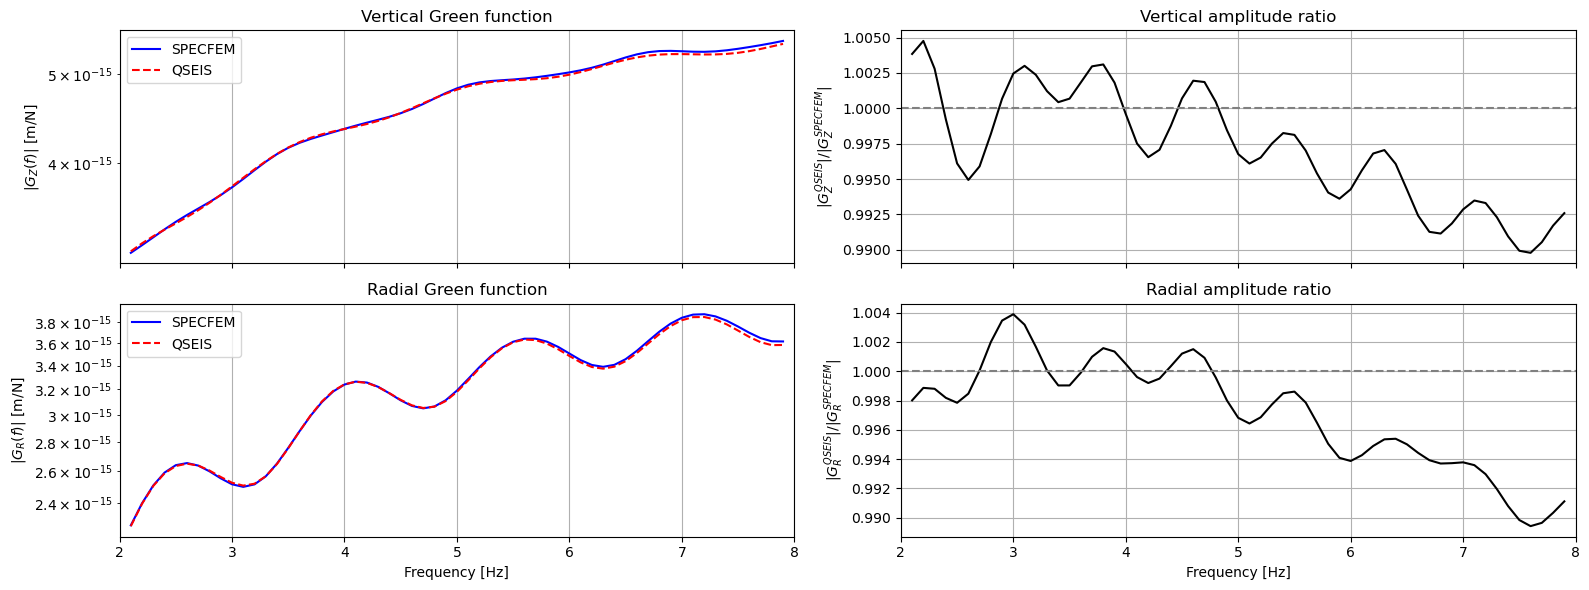

In [20]:
# ============================================================
# Direct QSEIS vs SPECFEM Green functions
# in the frequency domain
# ============================================================

# ============================================================
# 1. SPECFEM source function on SPECFEM seismogram grid
# ============================================================

# The saved source-time-function is sampled at the solver dt
# (~0.001 s), whereas the seismograms are sampled at ~0.01 s.
#
# Interpolate the exact SPECFEM STF onto tSpec so that
# displacement and source have:
#
#   - identical dt
#   - identical number of samples
#   - identical time origin
#

specStfInterp = interp1d(tStfSpec,stfSpec,kind="cubic",bounds_error=False,fill_value=0.0)
stfSpec_on_trace = specStfInterp(tSpec)

# ============================================================
# 2. QSEIS source function on QSEIS trace grid
# ============================================================

tauQ = 4.0 * dtQ
stfQ_on_trace = np.zeros_like(tQ)
ind = ((tQ > 0.0) &(tQ < tauQ))
stfQ_on_trace[ind] = (2.0 / tauQ *np.sin(np.pi * tQ[ind] / tauQ)**2)

# ============================================================
# 3. Choose QSEIS traces used for the GF
# ============================================================
#
# Use the tapered QSEIS traces if you created them in Cell 2.
# The taper only acts at late times (~20 s onward for 2 km).
#
# SPECFEM is used directly without any time taper.
# ============================================================

qZ_for_GF = qZ_taper
qR_for_GF = qR_taper

specZ_for_GF = specZ_raw
specR_for_GF = specR_raw

# ============================================================
# 4. FFTs on each solver's native grid
# ============================================================

# ----- SPECFEM -----

freqSpec = np.fft.rfftfreq(len(tSpec),dtSpec)
UZ_spec = np.fft.rfft(specZ_for_GF)
UR_spec = np.fft.rfft(specR_for_GF)
S_spec = np.fft.rfft(stfSpec_on_trace)

# ----- QSEIS -----
freqQ = np.fft.rfftfreq(len(tQ),dtQ)
UZ_q = np.fft.rfft(qZ_for_GF)
UR_q = np.fft.rfft(qR_for_GF)
S_q = np.fft.rfft(stfQ_on_trace)

# ============================================================
# 5. Deconvolve each solver by ITS OWN source function
# ============================================================
#
# We only care about 2–8 Hz, where both source spectra
# are comfortably non-zero.
#
# Therefore start with simple division:
#
#               G(f) = U(f) / S(f)
#
# No regularization yet.
# ============================================================
GZ_spec = UZ_spec / S_spec
GR_spec = UR_spec / S_spec

GZ_q = UZ_q / S_q
GR_q = UR_q / S_q

# ============================================================
# 6. Build a safe common frequency grid
# ============================================================

# QSEIS frequencies available inside requested band
selQ = ((freqQ >= FMIN) &(freqQ <= FMAX))
freqQ_band = freqQ[selQ]
fQmin = freqQ_band[0]
fQmax = freqQ_band[-1]
print("QSEIS available band:",fQmin, "to", fQmax, "Hz")

# Keep only SPECFEM bins that lie STRICTLY within
# the QSEIS interpolation range
selSpec = ((freqSpec >= fQmin) &(freqSpec <= fQmax))
freqCommon = freqSpec[selSpec]
print("Common comparison band:",freqCommon[0], "to", freqCommon[-1], "Hz")

# ============================================================
# 7. Interpolate complex QSEIS GF onto SPECFEM frequencies
# ============================================================

GZ_q_common = interp_complex(freqQ[selQ],GZ_q[selQ],freqCommon)

GR_q_common = interp_complex(freqQ[selQ],GR_q[selQ],freqCommon)


GZ_spec_common = GZ_spec[selSpec]
GR_spec_common = GR_spec[selSpec]

# ============================================================
# 8. Amplitude ratios
# ============================================================

ratioZ = (np.abs(GZ_q_common) /np.abs(GZ_spec_common))
ratioR = (np.abs(GR_q_common)/np.abs(GR_spec_common))

# ============================================================
# 9. Plot
# ============================================================

fig, ax = plt.subplots(2,2,figsize=(16, 6),sharex="col")

# ------------------------------------------------------------
# Vertical GF amplitude
# ------------------------------------------------------------

ax[0, 0].semilogy(freqCommon,np.abs(GZ_spec_common),color="blue",label="SPECFEM")
ax[0, 0].semilogy(freqCommon,np.abs(GZ_q_common),color="red",linestyle="--",label="QSEIS")
ax[0, 0].set_ylabel(r"$|G_Z(f)|$ [m/N]")
ax[0, 0].set_title("Vertical Green function")
ax[0, 0].grid()
ax[0, 0].legend()

# ------------------------------------------------------------
# Vertical amplitude ratio
# ------------------------------------------------------------

ax[0, 1].plot(freqCommon,ratioZ,color="black")
ax[0, 1].axhline(1.0,color="gray",linestyle="--")
ax[0, 1].set_ylabel(r"$|G_Z^{QSEIS}|/|G_Z^{SPECFEM}|$")
ax[0, 1].set_title("Vertical amplitude ratio")
ax[0, 1].grid()

# ------------------------------------------------------------
# Radial GF amplitude
# ------------------------------------------------------------

ax[1, 0].semilogy(freqCommon,np.abs(GR_spec_common),color="blue",label="SPECFEM")
ax[1, 0].semilogy(freqCommon,np.abs(GR_q_common),color="red",linestyle="--",label="QSEIS")
ax[1, 0].set_xlabel("Frequency [Hz]")
ax[1, 0].set_ylabel(r"$|G_R(f)|$ [m/N]")
ax[1, 0].set_title("Radial Green function")
ax[1, 0].grid()
ax[1, 0].legend()

# ------------------------------------------------------------
# Radial amplitude ratio
# ------------------------------------------------------------

ax[1, 1].plot(freqCommon,ratioR,color="black")
ax[1, 1].axhline(1.0,color="gray",linestyle="--")
ax[1, 1].set_xlabel("Frequency [Hz]")
ax[1, 1].set_ylabel(r"$|G_R^{QSEIS}|/|G_R^{SPECFEM}|$")
ax[1, 1].set_title("Radial amplitude ratio")
ax[1, 1].grid()

for a in ax.flat:
    a.set_xlim(FMIN, FMAX)

plt.tight_layout()
plt.show()

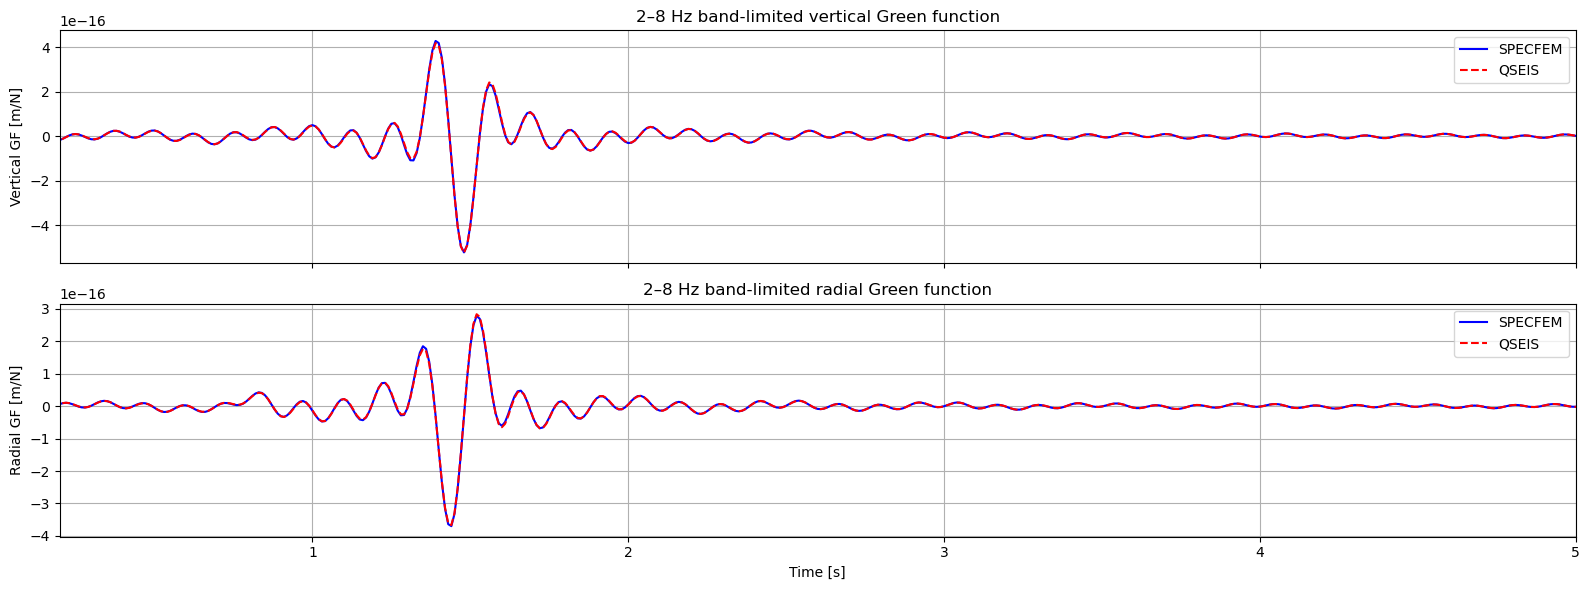

In [21]:
# ============================================================
# Reconstruct 2–8 Hz Green functions in time
# ============================================================

# We use the SPECFEM FFT grid because both Green functions
# have already been compared on that grid.

nSpec = len(tSpec)

# ============================================================
# 1. Create empty full spectra
# ============================================================

GZ_spec_band = np.zeros_like(GZ_spec,dtype=complex)
GR_spec_band = np.zeros_like(GR_spec,dtype=complex)

GZ_q_band = np.zeros_like(GZ_spec,dtype=complex)
GR_q_band = np.zeros_like(GR_spec,dtype=complex)

# ============================================================
# 2. Insert ONLY the common-frequency Green functions
# ============================================================
#
# selSpec corresponds exactly to freqCommon from Cell 5.
#

GZ_spec_band[selSpec] = GZ_spec_common
GR_spec_band[selSpec] = GR_spec_common

GZ_q_band[selSpec] = GZ_q_common
GR_q_band[selSpec] = GR_q_common


# ============================================================
# 3. Inverse FFT
# ============================================================

gZ_spec_time = np.fft.irfft(GZ_spec_band,n=nSpec)
gR_spec_time = np.fft.irfft(GR_spec_band,n=nSpec)

gZ_q_time = np.fft.irfft(GZ_q_band,n=nSpec)
gR_q_time = np.fft.irfft(GR_q_band,n=nSpec)

# ============================================================
# 4. Time axis for reconstructed Green functions
# ============================================================
#
# After deconvolution the source timing has been removed.
# Use a zero-based time axis for the reconstructed impulse
# responses.
#

tGF = np.arange(nSpec) * dtSpec

# ============================================================
# 5. Plot absolute amplitudes
# ============================================================

fig, ax = plt.subplots(2,1,figsize=(16, 6),sharex=True)

# ------------------------------------------------------------
# Vertical
# ------------------------------------------------------------

ax[0].plot(tGF,gZ_spec_time,color="blue",label="SPECFEM")
ax[0].plot(tGF,gZ_q_time,color="red",linestyle="--",label="QSEIS")

ax[0].set_ylabel("Vertical GF [m/N]")
ax[0].set_title("2–8 Hz band-limited vertical Green function")
ax[0].grid()
ax[0].legend()


# ------------------------------------------------------------
# Radial
# ------------------------------------------------------------

ax[1].plot(tGF,gR_spec_time,color="blue",label="SPECFEM")

ax[1].plot(tGF,gR_q_time,color="red",linestyle="--",label="QSEIS")
ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel("Radial GF [m/N]")
ax[1].set_title("2–8 Hz band-limited radial Green function")
ax[1].grid()
ax[1].legend()
ax[1].set_xlim(0.2,5)
plt.tight_layout()
plt.show()

Common dt      = 0.009999990000000292
Common samples = 1000
Common range   = -0.239999995 to 9.749990015000291 s
nfft = 2048
df   = 0.0488281738281724 Hz


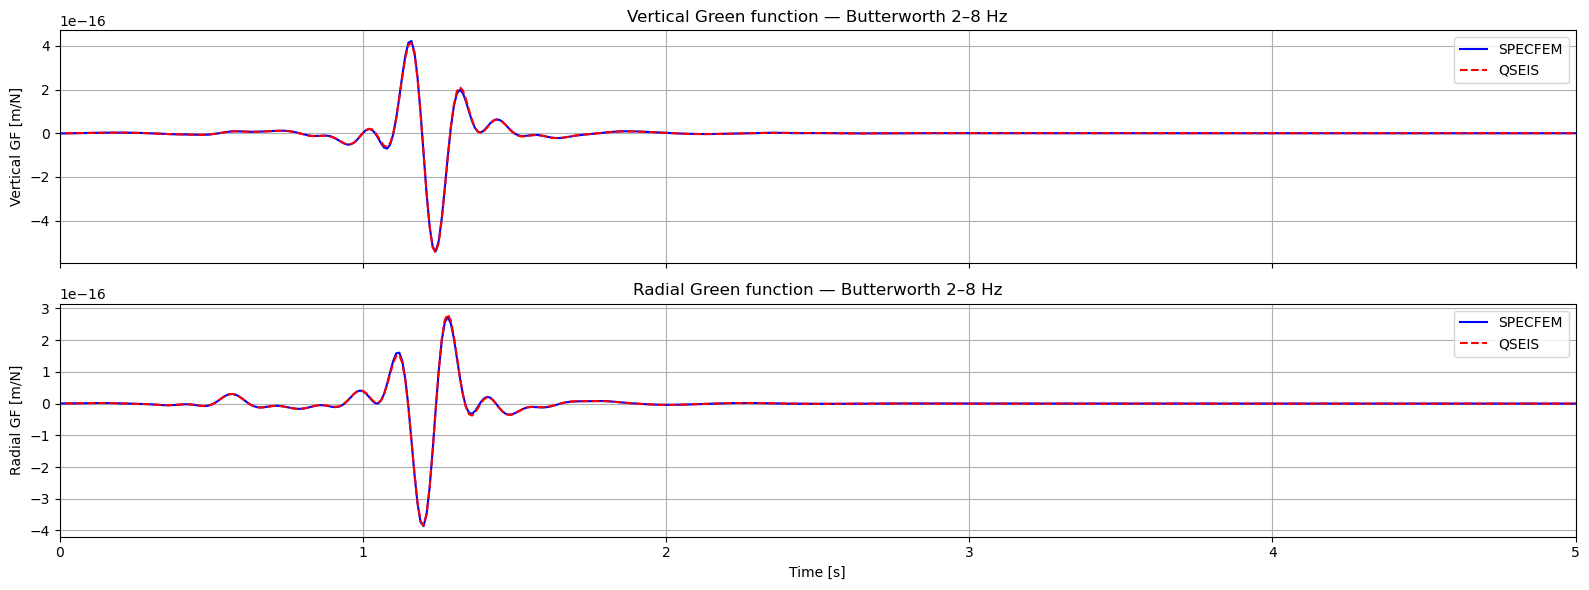

In [23]:
# ============================================================
# CELL — Common-grid deconvolved Green functions
# + zero-phase Butterworth 2–8 Hz
# ============================================================

# ============================================================
# 1. Common time grid
# ============================================================
#
# Use SPECFEM sampling because it is finer (~0.01 s).
#
# Keep the SPECFEM negative pre-source time because its
# source-time function is centred at t = 0.
# ============================================================

dtCommon = dtSpec

tMinCommon = min(tSpec[0], tQ[0])
tMaxCommon = min(tSpec[-1], tQ[-1])

tCommon = np.arange(tMinCommon,tMaxCommon + 0.5 * dtCommon,dtCommon)
nCommon = len(tCommon)
print("Common dt      =", dtCommon)
print("Common samples =", nCommon)
print("Common range   =", tCommon[0], "to", tCommon[-1], "s")

# ============================================================
# 2. Interpolate displacement traces onto common grid
# ============================================================

interpSpecZ = interp1d(tSpec,specZ_raw,kind="cubic",bounds_error=False,fill_value=0.0)
interpSpecR = interp1d(tSpec,specR_raw,kind="cubic",bounds_error=False,fill_value=0.0)
interpQZ = interp1d(tQ,qZ_taper,kind="cubic",bounds_error=False,fill_value=0.0)
interpQR = interp1d(tQ,qR_taper,kind="cubic",bounds_error=False,fill_value=0.0)

specZ_common = interpSpecZ(tCommon)
specR_common = interpSpecR(tCommon)

qZ_common = interpQZ(tCommon)
qR_common = interpQR(tCommon)

# ============================================================
# 3. SPECFEM STF on common grid
# ============================================================

interpSpecSTF = interp1d(tStfSpec,stfSpec,kind="cubic",bounds_error=False,fill_value=0.0)
stfSpec_common = interpSpecSTF(tCommon)

# ============================================================
# 4. QSEIS STF on common grid
# ============================================================
#
# IMPORTANT:
# pulse duration is still based on the ORIGINAL QSEIS dt.
# ============================================================

tauQ = 4.0 * dtQ
stfQ_common = np.zeros_like(tCommon)
ind = ((tCommon > 0.0) &(tCommon < tauQ))
stfQ_common[ind] = (2.0 / tauQ *np.sin(np.pi * tCommon[ind] / tauQ)**2)

# ============================================================
# 5. Zero padding
# ============================================================
#
# Use exactly the same nfft for both solvers.
# ============================================================

nfft = 2**int(np.ceil(np.log2(2 * nCommon)))
freqCommon = np.fft.rfftfreq(nfft,dtCommon)
print("nfft =", nfft)
print("df   =", freqCommon[1] - freqCommon[0], "Hz")

# ============================================================
# 6. FFT all signals on IDENTICAL grid
# ============================================================

UZ_spec = np.fft.rfft(specZ_common,n=nfft)
UR_spec = np.fft.rfft(specR_common,n=nfft)
UZ_q = np.fft.rfft(qZ_common,n=nfft)
UR_q = np.fft.rfft(qR_common,n=nfft)

S_spec = np.fft.rfft(stfSpec_common,n=nfft)
S_q = np.fft.rfft(stfQ_common,n=nfft)

# ============================================================
# 7. Stabilized source deconvolution
# ============================================================
#
# G = U S* / ( |S|^2 + epsilon )
#
# Both codes now use exactly the same FFT convention.
# ============================================================

powerSpec = np.abs(S_spec)**2
powerQ = np.abs(S_q)**2

epsSpec = 1.0e-8 * np.max(powerSpec)
epsQ = 1.0e-8 * np.max(powerQ)

GZ_spec = (UZ_spec * np.conj(S_spec)/(powerSpec + epsSpec))
GR_spec = (UR_spec * np.conj(S_spec)/(powerSpec + epsSpec))

GZ_q = (UZ_q*np.conj(S_q)/(powerQ + epsQ))
GR_q = (UR_q*np.conj(S_q)/(powerQ + epsQ))

# ============================================================
# 8. Build the zero-phase Butterworth response
# ============================================================
#
# Instead of a hard 2–8 Hz cut, use the smooth response
# corresponding to filtfilt.
# ============================================================

fsCommon = 1.0 / dtCommon
sos = butter(BUTTER_ORDER,[FMIN, FMAX],btype="bandpass",fs=fsCommon,output="sos")
_, H = sosfreqz(sos,worN=2.0 * np.pi * freqCommon / fsCommon)

# filtfilt amplitude response
B = np.abs(H)**2
# ============================================================
# 9. Apply the same smooth 2–8 Hz response to both GFs
# ============================================================

GZ_spec_filt = GZ_spec * B
GR_spec_filt = GR_spec * B

GZ_q_filt = GZ_q * B
GR_q_filt = GR_q * B

# ============================================================
# 10. Back to time domain
# ============================================================

gZ_spec = np.fft.irfft(GZ_spec_filt,n=nfft)[:nCommon]
gR_spec = np.fft.irfft(GR_spec_filt,n=nfft)[:nCommon]
gZ_q = np.fft.irfft(GZ_q_filt,n=nfft)[:nCommon]
gR_q = np.fft.irfft(GR_q_filt,n=nfft)[:nCommon]

# ============================================================
# 11. Plot
# ============================================================

fig, ax = plt.subplots(2,1,figsize=(16, 6),sharex=True)

# ------------------------------------------------------------
# Vertical
# ------------------------------------------------------------

ax[0].plot(tCommon,gZ_spec,color="blue",label="SPECFEM")
ax[0].plot(tCommon,gZ_q,color="red",linestyle="--",label="QSEIS")
ax[0].set_ylabel("Vertical GF [m/N]")
ax[0].set_title("Vertical Green function — Butterworth 2–8 Hz")
ax[0].grid()
ax[0].legend()

# ------------------------------------------------------------
# Radial
# ------------------------------------------------------------

ax[1].plot(tCommon,gR_spec,color="blue",label="SPECFEM")
ax[1].plot(tCommon,gR_q,color="red",linestyle="--",label="QSEIS")
ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel("Radial GF [m/N]")
ax[1].set_title("Radial Green function — Butterworth 2–8 Hz")
ax[1].grid()
ax[1].legend()
ax[1].set_xlim(0,5)
plt.tight_layout()
plt.show()